Loading C:\Users\shara\Downloads\Inputs\timeline_default.csv
Loaded rows: 87600
Saved plot to C:\Users\shara\Downloads\Inputs\demand_profile.png


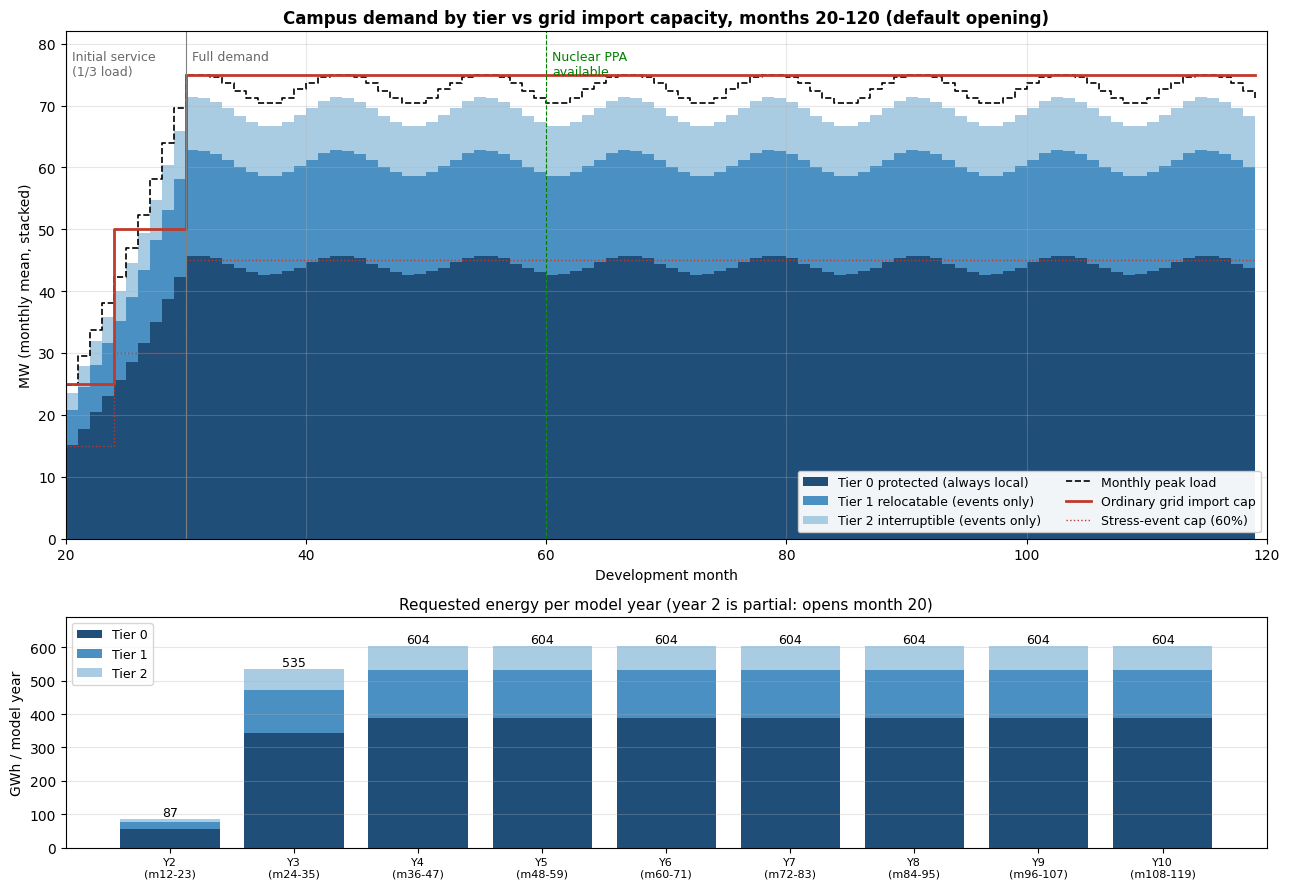

Horizon requested energy (m20-119): 4,853 GWh
Mature mean / peak: 69.0 / 75.0 MW
Hours where load > ordinary grid cap: 4,675; max shortfall 19.6 MW
Stress hours: 263
Max (load - 60% cap) during events: 29.5 MW
Tier 0 max during events: 50.9 MW


In [1]:
"""Demand profile, months 20-120 (default opening), from timeline_default.csv."""
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import tkinter as tk
from tkinter import filedialog

# ---------- pick the CSV with a file dialog ----------
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)
csv_file = filedialog.askopenfilename(
    title="Select timeline_default.csv",
    filetypes=[("CSV files", "*.csv"), ("All files", "*.*")],
)
root.destroy()

csv_path = Path(csv_file)
print("Loading", csv_path)
t = pd.read_csv(csv_path)
print("Loaded rows:", len(t))

t = t[t.development_month >= 20]

# ---------- monthly aggregation ----------
m = t.groupby("development_month").agg(
    tier0=("tier0_protected_mw", "mean"),
    tier1=("tier1_relocatable_mw", "mean"),
    tier2=("tier2_interruptible_mw", "mean"),
    peak=("load_mw", "max"),
    grid=("ordinary_grid_limit_mw", "max"),
)
months = m.index.values

fig, axes = plt.subplots(2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [2.2, 1]})
c0, c1, c2 = "#1f4e79", "#4a90c2", "#a9cce3"

# ---------- Panel 1: monthly mean demand by tier ----------
ax = axes[0]
ax.stackplot(
    months, m.tier0, m.tier1, m.tier2,
    colors=[c0, c1, c2], step="post",
    labels=["Tier 0 protected (always local)",
            "Tier 1 relocatable (events only)",
            "Tier 2 interruptible (events only)"],
)
ax.step(months, m.peak, where="post", color="black", lw=1.2, ls="--", label="Monthly peak load")
ax.step(months, m.grid, where="post", color="#c0392b", lw=2, label="Ordinary grid import cap")
ax.step(months, m.grid * 0.6, where="post", color="#c0392b", lw=1, ls=":",
        label="Stress-event cap (60%)")

ax.axvline(20, color="grey", lw=0.8)
ax.text(20.5, 79, "Initial service\n(1/3 load)", fontsize=9, va="top", color="dimgrey")
ax.axvline(30, color="grey", lw=0.8)
ax.text(30.5, 79, "Full demand", fontsize=9, va="top", color="dimgrey")
ax.axvline(60, color="green", lw=0.8, ls="--")
ax.text(60.5, 79, "Nuclear PPA\navailable", fontsize=9, va="top", color="green")

ax.set_xlim(20, 120)
ax.set_ylim(0, 82)
ax.set_xlabel("Development month")
ax.set_ylabel("MW (monthly mean, stacked)")
ax.set_title("Campus demand by tier vs grid import capacity, months 20-120 (default opening)",
             fontweight="bold")
ax.legend(loc="lower right", fontsize=9, ncol=2, framealpha=0.95)
ax.grid(alpha=0.3)

# ---------- Panel 2: annual energy ----------
ax = axes[1]
y = t.groupby("model_year").agg(
    t0=("tier0_protected_mw", "sum"),
    t1=("tier1_relocatable_mw", "sum"),
    t2=("tier2_interruptible_mw", "sum"),
) / 1000
ax.bar(y.index, y.t0, color=c0, label="Tier 0")
ax.bar(y.index, y.t1, bottom=y.t0, color=c1, label="Tier 1")
ax.bar(y.index, y.t2, bottom=y.t0 + y.t1, color=c2, label="Tier 2")

tot = y.sum(axis=1)
for yr, v in tot.items():
    ax.text(yr, v + 8, f"{v:,.0f}", ha="center", fontsize=9)

ax.set_xticks(y.index)
ax.set_xticklabels([f"Y{i}\n(m{(i-1)*12}-{i*12-1})" for i in y.index], fontsize=8)
ax.set_ylabel("GWh / model year")
ax.set_ylim(0, 690)
ax.set_title("Requested energy per model year (year 2 is partial: opens month 20)", fontsize=11)
ax.legend(fontsize=9, loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
out_png = csv_path.parent / "demand_profile.png"
plt.savefig(out_png, dpi=150)
print("Saved plot to", out_png)
plt.show()

# ---------- quick numbers ----------
print(f"Horizon requested energy (m20-119): {t.load_mw.sum() / 1e3:,.0f} GWh")
mature = t[t.development_month >= 30]
print(f"Mature mean / peak: {mature.load_mw.mean():.1f} / {t.load_mw.max():.1f} MW")

gap = (t.load_mw - t.ordinary_grid_limit_mw).clip(lower=0)
print(f"Hours where load > ordinary grid cap: {(gap > 0).sum():,}; max shortfall {gap.max():.1f} MW")

s = t[t.stress_active == 1]
event_gap = (s.load_mw - s.effective_grid_limit_mw).max()
print(f"Stress hours: {len(s)}")
print(f"Max (load - 60% cap) during events: {event_gap:.1f} MW")
print(f"Tier 0 max during events: {s.tier0_protected_mw.max():.1f} MW")